# WINE RECOGNITION DATASET

## Aim
To perform Exploratory Data Analysis (EDA), data preprocessing,
70:30 training-testing split and classification using machine
learning algorithms.

## Objective
To classify wine samples into three different classes using
machine learning algorithms.

## Dataset Information
- Dataset: Wine Recognition
- Source: UCI Machine Learning Repository
- Dataset ID: 109
- Total records: 178
- Input features: 13
- Target variable: Class
- Number of classes: 3
- Classification type: Multiclass Classification

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
# Fetch Wine Recognition dataset

wine_data = fetch_ucirepo(id=109)

X = wine_data.data.features.copy()
y = wine_data.data.targets.copy()

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [3]:
print("Input features:")
display(X.head())

print("\nTarget variable:")
display(y.head())

Input features:


,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735



Target variable:


,class
0,1
1,1
2,1
3,1
4,1


In [4]:
print("Number of records:", X.shape[0])
print("Number of input features:", X.shape[1])
print("Number of target columns:", y.shape[1])

Number of records: 178
Number of input features: 13
Number of target columns: 1


In [5]:
# Combine features and target

df = pd.concat(
    [
        X.reset_index(drop=True),
        y.reset_index(drop=True)
    ],
    axis=1
)

print("Combined dataset:")
display(df.head())

Combined dataset:


,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline,class
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [6]:
target_column = y.columns[0]

print("Target column:", target_column)

print("\nWine class distribution:")
print(df[target_column].value_counts())

print("\nNumber of classes:")
print(df[target_column].nunique())

Target column: class

Wine class distribution:
class
2    71
1    59
3    48
Name: count, dtype: int64

Number of classes:
3


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Alcohol                       178 non-null    float64
 1   Malicacid                     178 non-null    float64
 2   Ash                           178 non-null    float64
 3   Alcalinity_of_ash             178 non-null    float64
 4   Magnesium                     178 non-null    int64  
 5   Total_phenols                 178 non-null    float64
 6   Flavanoids                    178 non-null    float64
 7   Nonflavanoid_phenols          178 non-null    float64
 8   Proanthocyanins               178 non-null    float64
 9   Color_intensity               178 non-null    float64
 10  Hue                           178 non-null    float64
 11  0D280_0D315_of_diluted_wines  178 non-null    float64
 12  Proline                       178 non-null    int64  
 13  class           

In [8]:
print("Statistical summary:")
display(df.describe())

Statistical summary:


,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline,class
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,1.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,1.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,1.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,2.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,3.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,3.000000


In [9]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
Alcohol                         0
Malicacid                       0
Ash                             0
Alcalinity_of_ash               0
Magnesium                       0
Total_phenols                   0
Flavanoids                      0
Nonflavanoid_phenols            0
Proanthocyanins                 0
Color_intensity                 0
Hue                             0
0D280_0D315_of_diluted_wines    0
Proline                         0
class                           0
dtype: int64

Total missing values:
0


In [10]:
print("Number of duplicate records:", df.duplicated().sum())

Number of duplicate records: 0


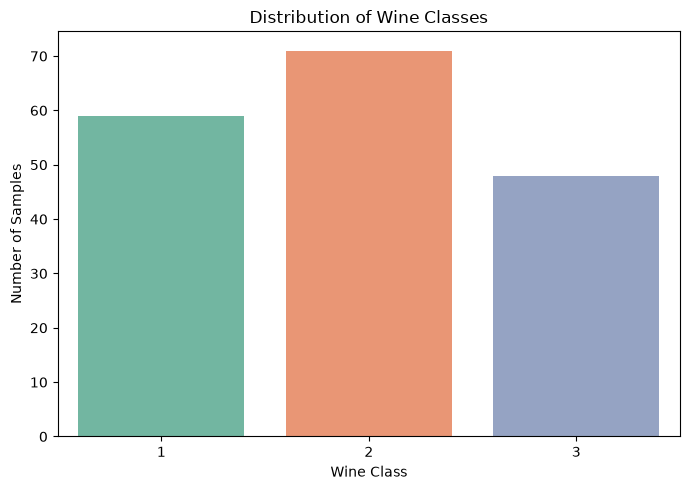

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=target_column,
    hue=target_column,
    palette="Set2",
    legend=False
)

plt.title("Distribution of Wine Classes")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

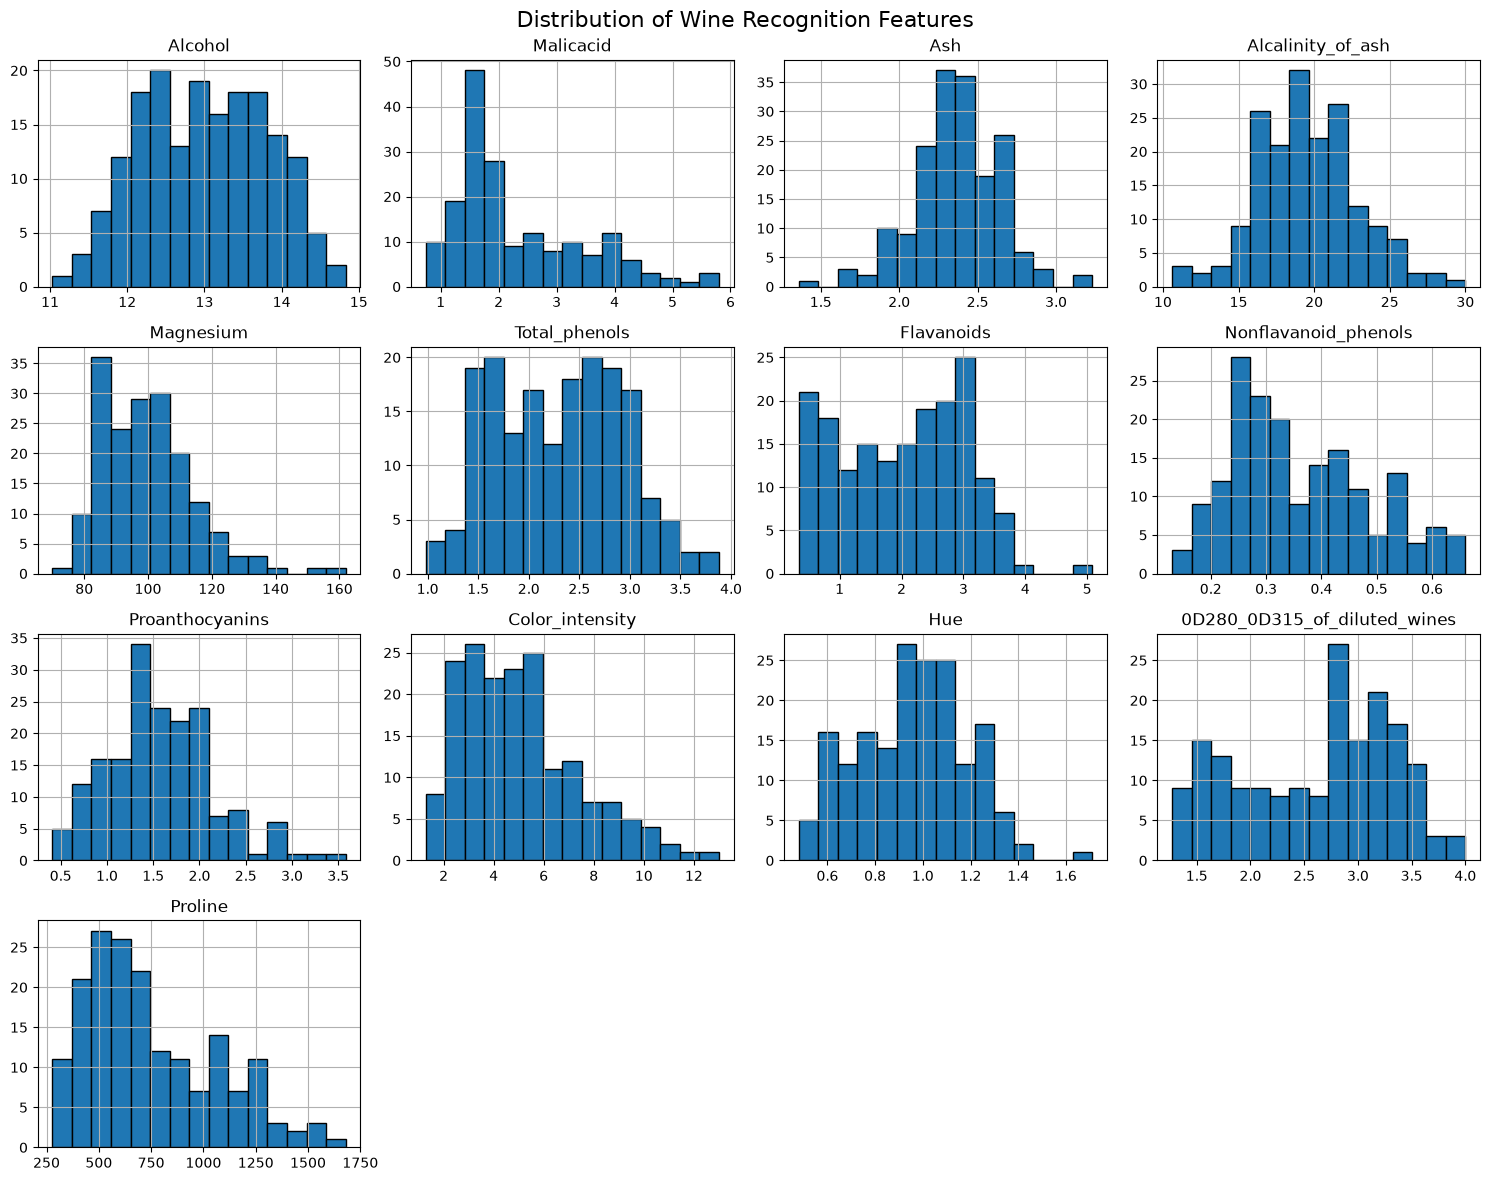

In [12]:
X.hist(
    figsize=(15, 12),
    bins=15,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Wine Recognition Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

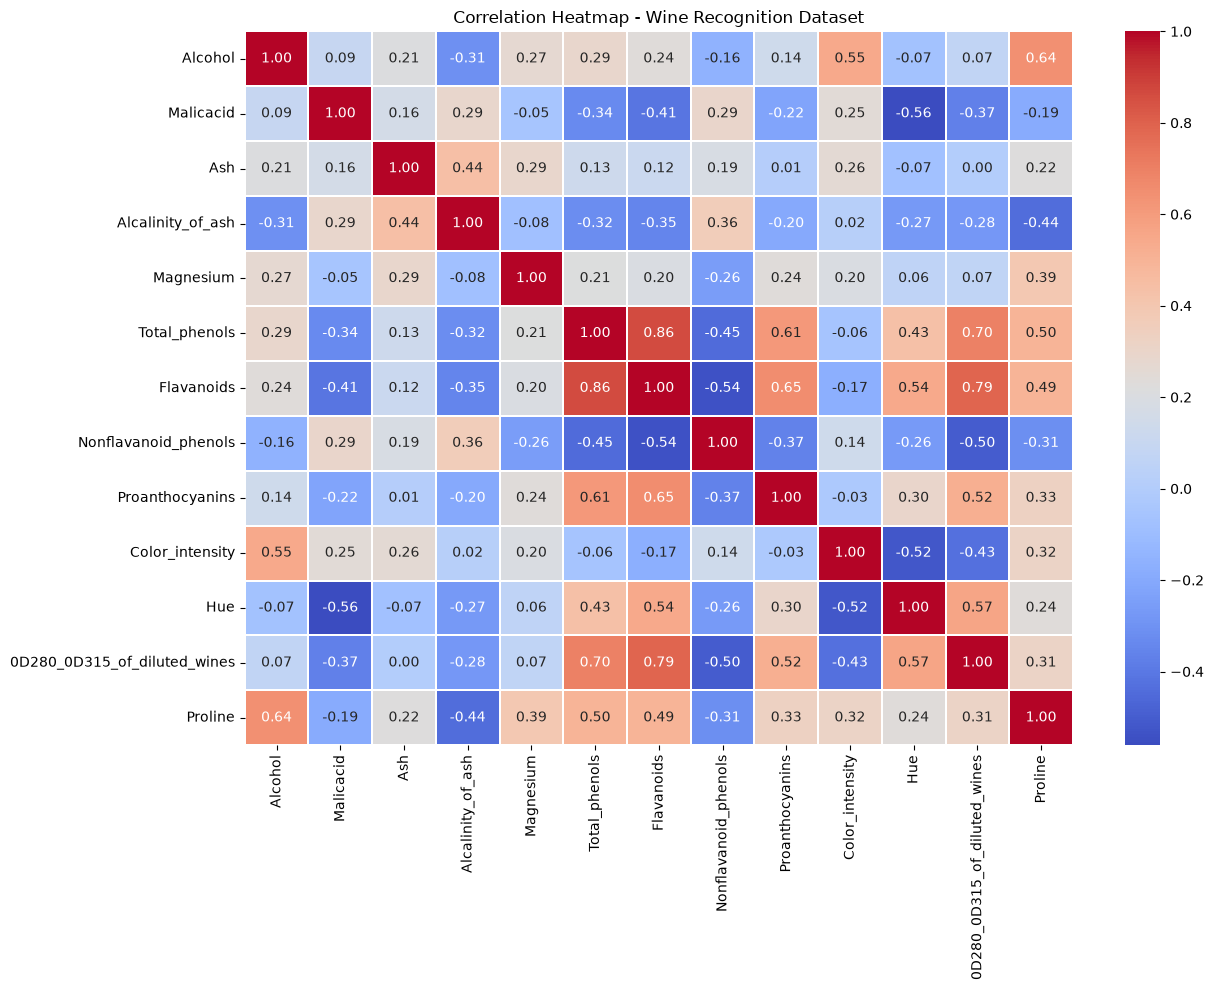

In [13]:
correlation = X.corr()

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.3
)

plt.title("Correlation Heatmap - Wine Recognition Dataset")
plt.tight_layout()
plt.show()

In [14]:
print("========== WINE RECOGNITION EDA SUMMARY ==========")

print("Total Records:", df.shape[0])
print("Total Input Features:", X.shape[1])
print("Target Variable:", target_column)
print("Number of Classes:", df[target_column].nunique())
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

print("\nWine Class Distribution:")
print(df[target_column].value_counts())

========== WINE RECOGNITION EDA SUMMARY ==========
Total Records: 178
Total Input Features: 13
Target Variable: class
Number of Classes: 3
Missing Values: 0
Duplicate Records: 0

Wine Class Distribution:
class
2    71
1    59
3    48
Name: count, dtype: int64


## EDA Observations

1. The Wine Recognition dataset contains 178 records and 13 input features.
2. The target variable is class, containing three categories: Class 1, Class 2 and Class 3.
3. The dataset contains no missing values.
4. No duplicate records were detected.
5. Class 1 contains 59 samples, Class 2 contains 71 samples and Class 3 contains 48 samples.
6. The target classes are reasonably balanced.
7. All 13 input features are numerical and can be standardized before classification.

In [15]:
# Separate input features and target variable

X = df.drop("class", axis=1)
y = df["class"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nWine class distribution:")
print(y.value_counts())

Input features shape: (178, 13)
Target shape: (178,)

Wine class distribution:
class
2    71
1    59
3    48
Name: count, dtype: int64


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training features: (124, 13)
Testing features: (54, 13)

Training class distribution:
class
2    50
1    41
3    33
Name: count, dtype: int64

Testing class distribution:
class
2    21
1    18
3    15
Name: count, dtype: int64


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")
print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled training data: (124, 13)
Scaled testing data: (54, 13)


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Support Vector Machine": SVC()
}

print("Four classification models are ready!")

Four classification models are ready!


In [19]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

results = []
trained_models = {}

for name, model in models.items():

    # Train the model
    model.fit(X_train_scaled, y_train)

    # Predict test data
    y_pred = model.predict(X_test_scaled)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    trained_models[name] = model

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        target_names=["Class 1", "Class 2", "Class 3"],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

     Class 1       0.95      1.00      0.97        18
     Class 2       1.00      0.95      0.98        21
     Class 3       1.00      1.00      1.00        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54


Decision Tree
              precision    recall  f1-score   support

     Class 1       1.00      0.94      0.97        18
     Class 2       0.91      1.00      0.95        21
     Class 3       1.00      0.93      0.97        15

    accuracy                           0.96        54
   macro avg       0.97      0.96      0.96        54
weighted avg       0.97      0.96      0.96        54


Random Forest
              precision    recall  f1-score   support

     Class 1       1.00      1.00      1.00        18
     Class 2       1.00      1.00      1.00        21
     Class 3       1.00 

In [20]:
results_df = pd.DataFrame(results)

print("WINE RECOGNITION MODEL PERFORMANCE COMPARISON")

display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)

WINE RECOGNITION MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,98.15%,98.25%,98.41%,98.29%
1,Decision Tree,96.30%,97.10%,95.93%,96.38%
2,Random Forest,100.00%,100.00%,100.00%,100.00%
3,Support Vector Machine,98.15%,98.48%,97.78%,98.08%


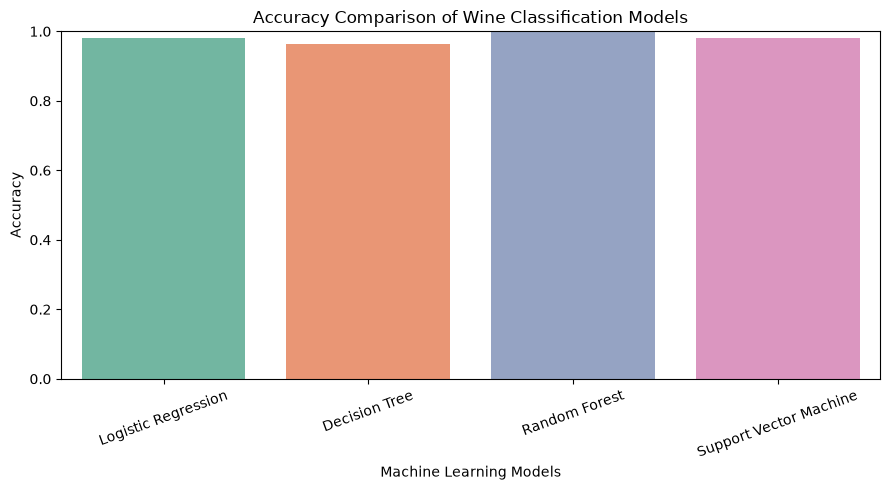

In [21]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy",
    hue="Model",
    palette="Set2",
    legend=False
)

plt.title("Accuracy Comparison of Wine Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

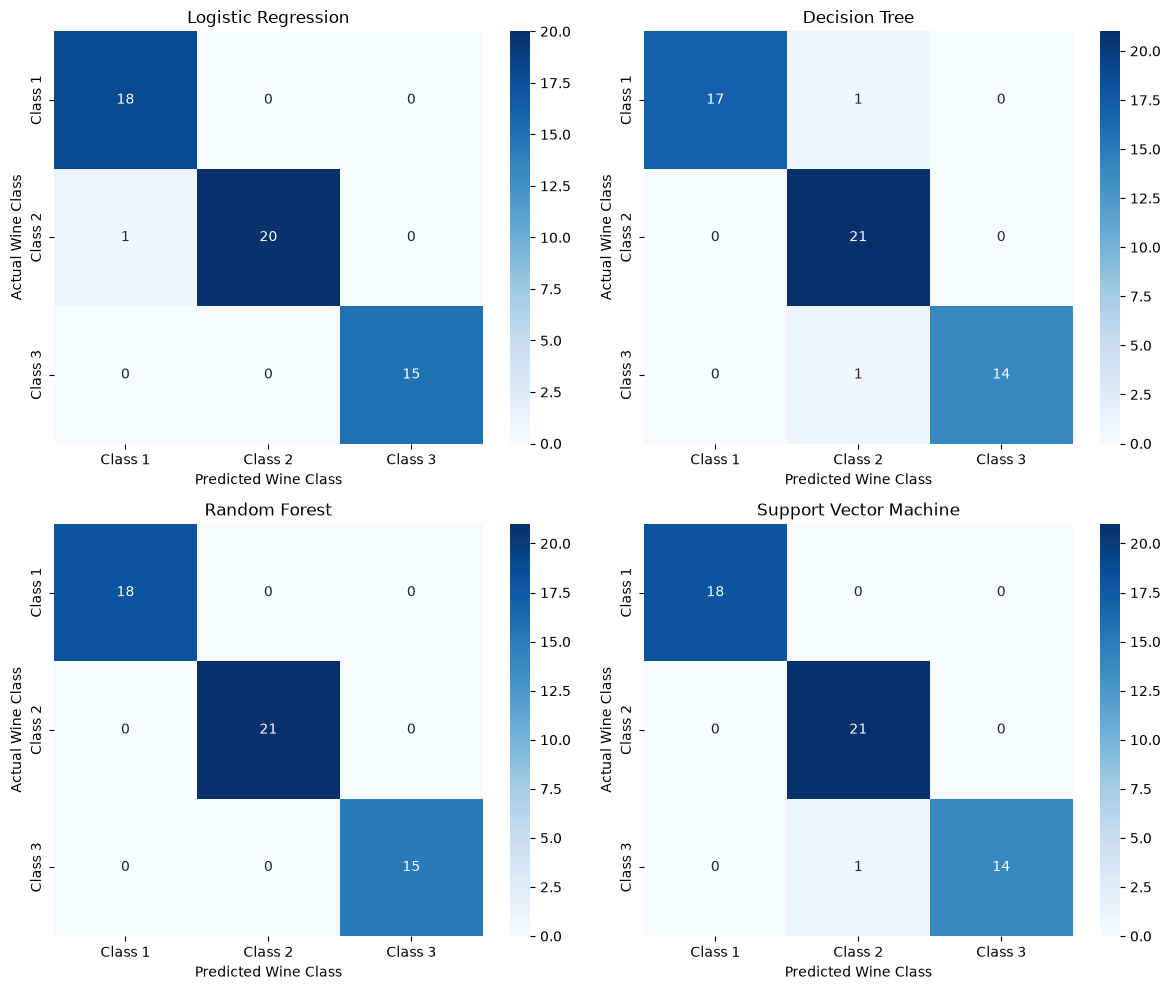

In [22]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

class_labels = [1, 2, 3]

for ax, (name, model) in zip(
    axes, trained_models.items()
):

    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Class 1", "Class 2", "Class 3"],
        yticklabels=["Class 1", "Class 2", "Class 3"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Wine Class")
    ax.set_ylabel("Actual Wine Class")

plt.tight_layout()
plt.show()

In [23]:
results_df.to_csv(
    "../results/wine_recognition_model_comparison.csv",
    index=False
)

print("Wine Recognition results saved successfully!")

Wine Recognition results saved successfully!


# Conclusion

The UCI Wine Recognition dataset was successfully analyzed
using Exploratory Data Analysis (EDA), data preprocessing
and machine learning classification techniques.

The dataset contains 178 records and 13 numerical input
features. The target variable is class, containing three
categories: Class 1, Class 2 and Class 3.

The dataset contained no missing values and no duplicate
records. The target classes were reasonably balanced.

The dataset was divided into 70% training data and 30%
testing data using stratified sampling. Feature scaling
was performed using StandardScaler.

Four classification algorithms were implemented:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine (SVM)

Among the four models, Random Forest achieved the highest
performance, with 100% accuracy, 100% macro precision,
100% macro recall and 100% macro F1-score on the test set.

Logistic Regression and Support Vector Machine also
performed well, achieving 98.15% accuracy.

Therefore, Random Forest was the best-performing model
in this experiment.

The results demonstrate that machine learning algorithms
can effectively classify wine samples using their
chemical characteristics.

However, the perfect Random Forest result is based on
a single train-test split and should be further validated
using cross-validation and independent test data.

This experiment is intended for academic machine learning
purposes.